# Deteksi Sampah dari Video CCTV — YOLO26 Small (`yolo26s`)

Alur sama seperti notebook sebelumnya, model diganti dari YOLOv8n ke **YOLO26s**:

1. Bangun dataset TACO (4 kelas: botol plastik, kaleng, bungkus, botol kaca)
2. Training `yolo26s.pt` + evaluasi per kelas
3. Upload video CCTV, ekstrak frame (buang frame yang hampir sama)
4. Auto-label frame CCTV pakai model hasil training (pseudo-label)
5. **Koreksi label manual** (wajib, kalau tidak model belajar dari kesalahannya sendiri)
6. Fine-tune dengan gabungan TACO + frame CCTV
7. Deteksi + tracking di video: hitung sampah unik dan sampah yang menetap

> Runtime: **GPU (T4)**. YOLO26 butuh `ultralytics >= 8.4.0`, sel install di bawah sudah menangani itu.

In [1]:
!pip -q install -U ultralytics opencv-python-headless pyyaml requests
!pip -q show ultralytics | grep -i ^version

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [2]:
import os, re, glob, shutil, zipfile, random, json, time, csv, subprocess
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

import cv2, numpy as np, torch, yaml, requests
from PIL import Image
from google.colab import files
from IPython.display import display, Video

# ===================== KONFIGURASI =====================
MODEL_NAME   = "yolo26s.pt"     # YOLO26 small (bobot COCO, otomatis terunduh)
EPOCHS       = 50               # training dari TACO
FT_EPOCHS    = 30               # fine-tune TACO + CCTV
IMGSZ        = 640
BATCH        = 16
PATIENCE     = 15
SEED         = 42

# Ekstraksi frame CCTV
FRAME_EVERY_SEC = 0.5           # ambil 1 frame tiap N detik
MIN_DIFF        = 1.0           # ambang beda antar-frame (makin besar = makin sedikit frame)
MAX_FRAMES      = 200
MAX_SIDE        = 1280          # sisi terpanjang frame yang disimpan (hemat ukuran untuk video 4K)

# Pseudo-label & fine-tune
PSEUDO_CONF  = 0.30
CCTV_REPEAT  = 5                # frame CCTV diulang N kali di train (jumlahnya kecil vs TACO)

# Deteksi + tracking
CONF         = 0.25
TRACKER      = "bytetrack.yaml"
MIN_HITS     = 5                # track dihitung "valid" kalau muncul >= N frame (buang flicker)
STATIC_SEC   = 2.0              # dianggap menetap kalau terlihat >= N detik
STATIC_MOVE  = 0.03             # ...dan bergeser < 3% diagonal frame
OUT_WIDTH    = 1280             # lebar maksimum video hasil

BASE      = "/content"
TACO_SRC  = Path(f"{BASE}/TACO")
TACO_RAW  = Path(f"{BASE}/taco_selected_images")
TACO_DIR  = Path(f"{BASE}/taco_yolo")
CCTV_DIR  = Path(f"{BASE}/cctv_yolo")
RAW_DIR   = Path(f"{BASE}/cctv_frames")
RUNS_DIR  = f"{BASE}/runs/detect"
RUN_NAME  = "yolo26s_taco"
FT_NAME   = "yolo26s_taco_cctv"
DRIVE_OUT = "/content/drive/MyDrive/taco_yolo"

CLASS_NAMES = ["botol_plastik", "kaleng_minuman", "bungkus_makanan", "botol_kaca"]
DEVICE = 0 if torch.cuda.is_available() else "cpu"

random.seed(SEED); np.random.seed(SEED)
print("Device:", DEVICE, "| Model:", MODEL_NAME)
if DEVICE == "cpu":
    print("PERINGATAN: GPU tidak aktif. Runtime > Change runtime type > T4 GPU.")

Device: 0 | Model: yolo26s.pt


## 1. Dataset TACO (4 kelas)

In [3]:
if not TACO_SRC.exists():
    !git clone --depth 1 https://github.com/pedropro/TACO.git {TACO_SRC}
else:
    print("Repo TACO sudah ada:", TACO_SRC)

Cloning into '/content/TACO'...
remote: Enumerating objects: 31, done.
remote: Counting objects: 100% (31/31), done.
remote: Compressing objects: 100% (30/30), done.
remote: Total 31 (delta 2), reused 10 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (31/31), 22.79 MiB | 7.76 MiB/s, done.
Resolving deltas: 100% (2/2), done.


In [4]:
REBUILD_TACO = False   # True = unduh ulang & bangun ulang dataset

def map_category(category_name):
    name = category_name.lower().strip()
    if "glass bottle" in name:                 # cek botol kaca dulu sebelum botol lain
        return 3
    if "plastic bottle" in name:
        return 0
    if name in {"drink can", "can"}:           # "Bottle" umum sengaja tidak dipetakan (material ambigu)
        return 1
    wrapper_terms = ["crisp packet", "other plastic wrapper", "plastic wrapper",
                     "plastic film", "wrapping paper"]   # proksi bungkus/kemasan
    if any(t in name for t in wrapper_terms):
        return 2
    return None


def build_taco():
    ann_file = TACO_SRC / "data" / "annotations.json"
    if not ann_file.exists():
        raise FileNotFoundError(f"Anotasi tidak ditemukan: {ann_file}")
    coco = json.loads(ann_file.read_text(encoding="utf-8"))

    category_map = {}
    print("=== KATEGORI TACO YANG DIPETAKAN ===")
    for cat in coco["categories"]:
        m = map_category(cat["name"])
        if m is not None:
            category_map[cat["id"]] = m
            print(f'{cat["name"]} -> {CLASS_NAMES[m]}')
    if not category_map:
        raise ValueError("Tidak ada kategori yang cocok. Periksa nama kategori anotasi TACO.")

    images_by_id = {im["id"]: im for im in coco["images"]}
    anns_by_image = defaultdict(list)
    for ann in coco["annotations"]:
        bbox = ann.get("bbox")
        if (ann.get("category_id") in category_map and ann.get("image_id") in images_by_id
                and bbox and len(bbox) == 4 and bbox[2] > 0 and bbox[3] > 0):
            anns_by_image[ann["image_id"]].append(ann)
    print("\nGambar dengan anotasi terpilih:", len(anns_by_image))

    for d in (TACO_RAW, TACO_DIR):
        shutil.rmtree(d, ignore_errors=True)
    TACO_RAW.mkdir(parents=True)
    for split in ("train", "val"):
        (TACO_DIR / "images" / split).mkdir(parents=True)
        (TACO_DIR / "labels" / split).mkdir(parents=True)

    # ---- unduh gambar (paralel) ----
    headers = {"User-Agent": "Mozilla/5.0"}

    def download_one(image_id):
        info = images_by_id[image_id]
        out = TACO_RAW / f"image_{image_id}.jpg"
        for url in [info.get("flickr_640_url"), info.get("flickr_url")]:
            if not url:
                continue
            for _ in range(2):
                try:
                    r = requests.get(url, timeout=30, headers=headers)
                    r.raise_for_status()
                    if not r.headers.get("Content-Type", "").lower().startswith("image/") or not r.content:
                        continue
                    out.write_bytes(r.content)
                    with Image.open(out) as im:
                        im.verify()
                    return image_id, out
                except Exception:
                    time.sleep(0.5)
        return image_id, None

    ids = sorted(anns_by_image)
    downloaded, failed = {}, []
    with ThreadPoolExecutor(max_workers=8) as ex:
        for i, (iid, path) in enumerate(ex.map(download_one, ids), 1):
            (downloaded.__setitem__(iid, path) if path else failed.append(iid))
            if i % 100 == 0 or i == len(ids):
                print(f"Download: {i}/{len(ids)}")
    print("Berhasil:", len(downloaded), "| Gagal:", len(failed))
    if len(downloaded) < 5:
        raise RuntimeError("Gambar yang berhasil diunduh terlalu sedikit. Periksa koneksi.")

    # ---- split 80/20 ----
    image_ids = list(downloaded)
    random.shuffle(image_ids)
    sp = max(1, min(int(len(image_ids) * 0.8), len(image_ids) - 1))
    splits = {"train": image_ids[:sp], "val": image_ids[sp:]}

    # ---- COCO -> YOLO ----
    saved = 0
    for split, split_ids in splits.items():
        for iid in split_ids:
            src = downloaded[iid]
            try:
                with Image.open(src) as im:
                    W, H = im.size
            except Exception:
                continue
            lines = []
            for ann in anns_by_image[iid]:
                cid = category_map[ann["category_id"]]
                x, y, w, h = ann["bbox"]
                x1, y1 = max(0.0, min(W, x)), max(0.0, min(H, y))
                x2, y2 = max(0.0, min(W, x + w)), max(0.0, min(H, y + h))
                bw, bh = x2 - x1, y2 - y1
                if bw <= 0 or bh <= 0:
                    continue
                lines.append(f"{cid} {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {bw/W:.6f} {bh/H:.6f}")
            if lines:
                shutil.copy2(src, TACO_DIR / "images" / split / f"image_{iid}.jpg")
                (TACO_DIR / "labels" / split / f"image_{iid}.txt").write_text("\n".join(lines), encoding="utf-8")
                saved += 1

    yaml_data = {"path": str(TACO_DIR), "train": "images/train", "val": "images/val",
                 "names": {i: n for i, n in enumerate(CLASS_NAMES)}}
    (TACO_DIR / "data.yaml").write_text(yaml.safe_dump(yaml_data, sort_keys=False, allow_unicode=True), encoding="utf-8")
    print("\n=== DATASET SELESAI ===", "| gambar tersimpan:", saved)


if REBUILD_TACO or not (TACO_DIR / "data.yaml").exists():
    build_taco()
else:
    print("Dataset TACO sudah ada, dilewati:", TACO_DIR)

DATA_YAML = str(TACO_DIR / "data.yaml")

=== KATEGORI TACO YANG DIPETAKAN ===
Other plastic bottle -> botol_plastik
Clear plastic bottle -> botol_plastik
Glass bottle -> botol_kaca
Plastic bottle cap -> botol_plastik
Drink can -> kaleng_minuman
Wrapping paper -> bungkus_makanan
Plastic film -> bungkus_makanan
Other plastic wrapper -> bungkus_makanan
Crisp packet -> bungkus_makanan

Gambar dengan anotasi terpilih: 901
Download: 100/901
Download: 200/901
Download: 300/901
Download: 400/901
Download: 500/901
Download: 600/901
Download: 700/901
Download: 800/901
Download: 900/901
Download: 901/901
Berhasil: 901 | Gagal: 0

=== DATASET SELESAI === | gambar tersimpan: 294


In [5]:
# Cek distribusi anotasi per kelas (train & val)
for split in ("train", "val"):
    counts = Counter()
    for f in (TACO_DIR / "labels" / split).glob("*.txt"):
        for line in f.read_text().splitlines():
            if line.strip():
                counts[int(line.split()[0])] += 1
    n_img = len(list((TACO_DIR / "images" / split).glob("*")))
    print(f"\n[{split}] {n_img} gambar")
    for i, n in enumerate(CLASS_NAMES):
        print(f"  {n:<16}: {counts[i]} anotasi")
    if split == "train" and any(counts[i] == 0 for i in range(len(CLASS_NAMES))):
        print("  PERINGATAN: ada kelas tanpa anotasi. Jangan training dulu.")


[train] 238 gambar
  botol_plastik   : 123 anotasi
  kaleng_minuman  : 53 anotasi
  bungkus_makanan : 249 anotasi
  botol_kaca      : 16 anotasi

[val] 56 gambar
  botol_plastik   : 33 anotasi
  kaleng_minuman  : 8 anotasi
  bungkus_makanan : 82 anotasi
  botol_kaca      : 1 anotasi


## 2. Training YOLO26s

In [6]:
from ultralytics import YOLO

model = YOLO(MODEL_NAME)
model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    workers=2,
    project=RUNS_DIR,
    name=RUN_NAME,
    exist_ok=True,
    seed=SEED,
    patience=PATIENCE,
    plots=True,
    amp=True,
    verbose=True,
)

BEST_TACO = f"{RUNS_DIR}/{RUN_NAME}/weights/best.pt"
print("Model ditemukan:", os.path.exists(BEST_TACO), "|", BEST_TACO)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/taco_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fr

In [7]:
# Evaluasi per kelas di validation set
m = YOLO(BEST_TACO)
metrics = m.val(data=DATA_YAML, imgsz=IMGSZ, device=DEVICE, plots=True, verbose=False)

print(f"\nmAP50: {metrics.box.map50:.3f} | mAP50-95: {metrics.box.map:.3f} | "
      f"P: {metrics.box.mp:.3f} | R: {metrics.box.mr:.3f}\n")
for i, c in enumerate(metrics.box.ap_class_index):
    print(f"{metrics.names[int(c)]:<16} AP50={metrics.box.ap50[i]:.3f}  AP50-95={metrics.box.ap[i]:.3f}")

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5053.5±566.2 MB/s, size: 4037.6 KB)
val: Scanning /content/taco_yolo/labels/val.cache... 56 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 56/56 21.4Mit/s 0.0s
val: /content/taco_yolo/images/val/image_296.jpg: corrupt JPEG restored and saved
val: /content/taco_yolo/images/val/image_299.jpg: corrupt JPEG restored and saved
val: /content/taco_yolo/images/val/image_335.jpg: corrupt JPEG restored and saved
val: /content/taco_yolo/images/val/image_421.jpg: corrupt JPEG restored and saved
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.0s/it 7.8s
                   all         56        124      0.228      0.181      0.154      0.119
Speed: 8.1ms preprocess, 20.1ms inference, 0.0ms loss, 4.3ms postprocess pe

In [8]:
# Cadangkan bobot ke Google Drive (opsional, aman kalau gagal)
try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(DRIVE_OUT, exist_ok=True)
    shutil.copy2(BEST_TACO, f"{DRIVE_OUT}/yolo26s_taco_best.pt")
    print("Tersimpan di:", f"{DRIVE_OUT}/yolo26s_taco_best.pt")
except Exception as e:
    print("Backup ke Drive dilewati:", repr(e))

Mounted at /content/drive
Tersimpan di: /content/drive/MyDrive/taco_yolo/yolo26s_taco_best.pt


## 3. Video CCTV: upload dan ekstrak frame

Saving hasil_video_baru.mp4 to hasil_video_baru.mp4
File     : hasil_video_baru.mp4 (0.64 MB)
Resolusi : 768x432 | FPS: 29.97 | Frame: 357 | Durasi: 11.9 dtk


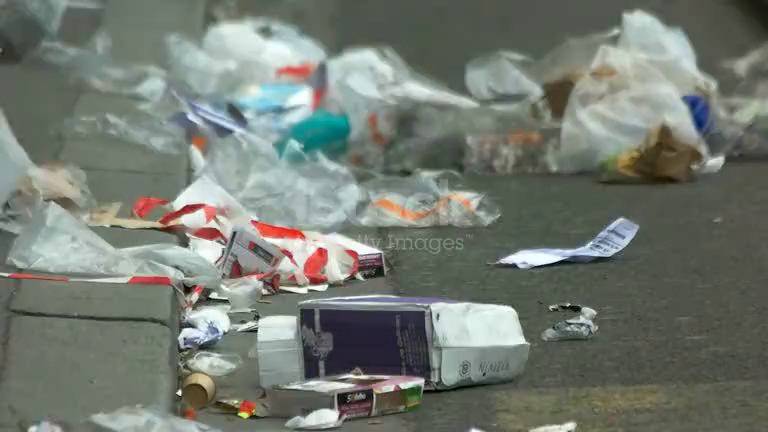

In [10]:
up = files.upload()
name = next(iter(up.keys()))
VIDEO_PATH = f"{BASE}/{name}"

cap = cv2.VideoCapture(VIDEO_PATH)
if not cap.isOpened():
    raise RuntimeError("Video gagal dibuka. Format atau codec tidak didukung.")
FPS = cap.get(cv2.CAP_PROP_FPS) or 25
N   = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
W   = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H   = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
print(f"File     : {name} ({os.path.getsize(VIDEO_PATH)/1024**2:.2f} MB)")
print(f"Resolusi : {W}x{H} | FPS: {FPS:.2f} | Frame: {N} | Durasi: {N/FPS:.1f} dtk")

ok, frame = cap.read()
cap.release()
if ok:
    from google.colab.patches import cv2_imshow
    cv2_imshow(cv2.resize(frame, (min(W, 960), int(H * min(W, 960) / W))))

In [11]:
# Ekstrak frame: 1 frame tiap FRAME_EVERY_SEC, buang yang hampir sama dengan frame sebelumnya
shutil.rmtree(RAW_DIR, ignore_errors=True); RAW_DIR.mkdir(parents=True)

cap = cv2.VideoCapture(VIDEO_PATH)
step = max(1, int(round(FPS * FRAME_EVERY_SEC)))
prev, saved, idx = None, 0, 0

while saved < MAX_FRAMES:
    ok, frame = cap.read()
    if not ok:
        break
    if idx % step == 0:
        small = cv2.resize(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), (96, 54)).astype(np.float32)
        if prev is None or np.abs(small - prev).mean() > MIN_DIFF:
            h, w = frame.shape[:2]
            if max(h, w) > MAX_SIDE:
                s = MAX_SIDE / max(h, w)
                frame = cv2.resize(frame, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)
            cv2.imwrite(str(RAW_DIR / f"f_{idx:07d}.jpg"), frame, [cv2.IMWRITE_JPEG_QUALITY, 95])
            saved += 1
        prev = small          # pembanding selalu frame sampel sebelumnya
    idx += 1
cap.release()

print(f"Total frame video: {N} | diperiksa: {len(range(0, idx, step))} | tersimpan: {saved}")
print("Folder:", RAW_DIR)

Total frame video: 357 | diperiksa: 24 | tersimpan: 24
Folder: /content/cctv_frames


## 4. Pseudo-label (model YOLO26s melabeli frame CCTV)

In [12]:
base = YOLO(BEST_TACO)

frames = sorted(glob.glob(f"{RAW_DIR}/*.jpg"))
LAB_ALL = Path(f"{BASE}/cctv_labels_auto")
shutil.rmtree(LAB_ALL, ignore_errors=True); LAB_ALL.mkdir(parents=True)

n_box, per_cls = 0, Counter()
for i in range(0, len(frames), 16):
    for r in base.predict(frames[i:i + 16], conf=PSEUDO_CONF, imgsz=IMGSZ, device=DEVICE, verbose=False):
        stem = Path(r.path).stem
        xywhn = r.boxes.xywhn.cpu().numpy()
        cls   = r.boxes.cls.int().cpu().numpy()
        lines = [f"{c} {x:.6f} {y:.6f} {w:.6f} {h:.6f}" for c, (x, y, w, h) in zip(cls, xywhn)]
        (LAB_ALL / f"{stem}.txt").write_text("\n".join(lines))
        n_box += len(lines); per_cls.update(cls.tolist())

print(f"Auto-label selesai: {len(frames)} frame, {n_box} box")
for i, n in enumerate(CLASS_NAMES):
    print(f"  {n:<16}: {per_cls[i]}")

# Paket untuk dikoreksi (Roboflow / CVAT / LabelImg): gambar + label YOLO + classes.txt
PKG = f"{BASE}/cctv_review.zip"
with zipfile.ZipFile(PKG, "w", zipfile.ZIP_DEFLATED) as z:
    for f in frames:
        z.write(f, f"images/{os.path.basename(f)}")
    for f in LAB_ALL.glob("*.txt"):
        z.write(f, f"labels/{f.name}")
    z.writestr("classes.txt", "\n".join(CLASS_NAMES) + "\n")
print("Paket review:", PKG)
files.download(PKG)

Auto-label selesai: 24 frame, 28 box
  botol_plastik   : 0
  kaleng_minuman  : 0
  bungkus_makanan : 28
  botol_kaca      : 0
Paket review: /content/cctv_review.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Koreksi label (manual)
Buka `cctv_review.zip` di Roboflow / CVAT / LabelImg: hapus box yang salah, tambah box yang terlewat, lalu export format **YOLO** (YOLOv8 / YOLO26 sama saja) dan upload zip hasilnya di sel berikut.

Urutan ID kelas harus tetap: `0 botol_plastik`, `1 kaleng_minuman`, `2 bungkus_makanan`, `3 botol_kaca`.

Kalau mau coba cepat tanpa koreksi, set `USE_REVIEWED = False` (hasilnya kurang bisa dipercaya).

## 5. Fine-tune TACO + CCTV

In [14]:
USE_REVIEWED = True    # False = pakai pseudo-label apa adanya

LABEL_SRC = Path(f"{BASE}/cctv_labels_reviewed")
shutil.rmtree(LABEL_SRC, ignore_errors=True); LABEL_SRC.mkdir(parents=True)

def clean_stem(stem):
    # Roboflow menambah akhiran: f_0000030_jpg.rf.abc123 -> f_0000030
    return re.sub(r"_(jpg|jpeg|png)\.rf\..*$", "", stem)

if USE_REVIEWED:
    up = files.upload()
    zname = next(iter(up))
    ex_dir = Path(f"{BASE}/cctv_reviewed"); shutil.rmtree(ex_dir, ignore_errors=True)
    zipfile.ZipFile(zname).extractall(ex_dir)
    txts = [t for t in glob.glob(f"{ex_dir}/**/*.txt", recursive=True)
            if os.path.basename(t).lower() not in ("classes.txt", "labels.txt", "readme.txt")]
    src_files = txts
else:
    src_files = [str(p) for p in LAB_ALL.glob("*.txt")]

n_lab, n_box, bad = 0, 0, 0
for t in src_files:
    keep = []
    for line in Path(t).read_text().splitlines():
        p = line.split()
        if len(p) == 5 and p[0].isdigit() and int(p[0]) < len(CLASS_NAMES):
            keep.append(line.strip())
        elif line.strip():
            bad += 1
    (LABEL_SRC / f"{clean_stem(Path(t).stem)}.txt").write_text("\n".join(keep))
    n_lab += 1; n_box += len(keep)

print(f"File label: {n_lab} | box: {n_box} | baris tidak valid dibuang: {bad}")

Saving cctv_review (2).zip to cctv_review (2).zip
File label: 24 | box: 28 | baris tidak valid dibuang: 0


In [15]:
# Bangun dataset CCTV: hanya frame yang punya file label (file kosong = frame tanpa sampah / background)
stems = sorted(p.stem for p in RAW_DIR.glob("*.jpg") if (LABEL_SRC / f"{p.stem}.txt").exists())
print("Frame berlabel:", len(stems), "dari", len(list(RAW_DIR.glob('*.jpg'))))

FINAL_MODEL = BEST_TACO
if len(stems) < 4:
    print("Frame berlabel terlalu sedikit, fine-tune dilewati. Memakai model TACO.")
else:
    # Split berurutan (bukan acak): frame bertetangga hampir sama, acak = kebocoran ke val
    n_val = max(1, int(round(len(stems) * 0.2)))
    split_stems = {"train": stems[:-n_val], "val": stems[-n_val:]}

    shutil.rmtree(CCTV_DIR, ignore_errors=True)
    for split, sl in split_stems.items():
        (CCTV_DIR / "images" / split).mkdir(parents=True)
        (CCTV_DIR / "labels" / split).mkdir(parents=True)
        reps = CCTV_REPEAT if split == "train" else 1
        for s in sl:
            for r in range(reps):
                tag = f"_r{r}" if reps > 1 else ""
                shutil.copy2(RAW_DIR / f"{s}.jpg", CCTV_DIR / "images" / split / f"{s}{tag}.jpg")
                shutil.copy2(LABEL_SRC / f"{s}.txt", CCTV_DIR / "labels" / split / f"{s}{tag}.txt")

    MIX_YAML = f"{BASE}/data_mix.yaml"
    Path(MIX_YAML).write_text(yaml.safe_dump({
        "path": BASE,
        "train": [str(TACO_DIR / "images/train"), str(CCTV_DIR / "images/train")],
        "val":   [str(TACO_DIR / "images/val"),   str(CCTV_DIR / "images/val")],
        "names": {i: n for i, n in enumerate(CLASS_NAMES)},
    }, sort_keys=False))
    print(f"CCTV train: {len(split_stems['train'])} frame x{CCTV_REPEAT} | val: {len(split_stems['val'])} frame")

    ft = YOLO(BEST_TACO)
    ft.train(
        data=MIX_YAML, epochs=FT_EPOCHS, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=2,
        project=RUNS_DIR, name=FT_NAME, exist_ok=True, seed=SEED, patience=PATIENCE,
        freeze=10,          # backbone dibekukan: data CCTV sedikit, cegah overfitting
        plots=True, amp=True, verbose=True,
    )
    cand = f"{RUNS_DIR}/{FT_NAME}/weights/best.pt"
    if os.path.exists(cand):
        FINAL_MODEL = cand

print("Model final:", FINAL_MODEL)
try:
    os.makedirs(DRIVE_OUT, exist_ok=True)
    shutil.copy2(FINAL_MODEL, f"{DRIVE_OUT}/yolo26s_final_best.pt")
    print("Backup Drive:", f"{DRIVE_OUT}/yolo26s_final_best.pt")
except Exception as e:
    print("Backup Drive dilewati:", repr(e))

Frame berlabel: 24 dari 24
CCTV train: 19 frame x5 | val: 5 frame
Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data_mix.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs/detect/yolo26s_taco/weights/best.pt, momentum=0.937

## 6. Deteksi + tracking + hitung sampah

- **Unik**: jumlah ID track berbeda (track yang muncul < `MIN_HITS` frame dibuang sebagai flicker)
- **Menetap**: track yang terlihat >= `STATIC_SEC` detik dan hampir tidak bergeser (< `STATIC_MOVE` dari diagonal frame)

In [16]:
def detect_video(video_path, tag="hasil", model_path=None):
    mdl = YOLO(model_path or FINAL_MODEL)
    names = mdl.names

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise RuntimeError(f"Video tidak bisa dibuka: {video_path}")
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()

    sc = min(1.0, OUT_WIDTH / W)
    ow, oh = int(W * sc) // 2 * 2, int(H * sc) // 2 * 2
    diag = float(np.hypot(W, H))
    fs = max(0.45, ow / 1280 * 0.6)          # skala font
    th = max(1, round(ow / 640))             # tebal garis

    palette = [(0, 170, 255), (80, 220, 80), (255, 140, 40), (230, 80, 200), (80, 200, 255)]
    raw_out = f"{BASE}/{tag}_raw.mp4"
    writer = cv2.VideoWriter(raw_out, cv2.VideoWriter_fourcc(*"mp4v"), fps, (ow, oh))

    tracks = {}   # id -> info

    def is_static(t):
        span = (t["last"] - t["first"] + 1) / fps
        ext = np.hypot(t["maxx"] - t["minx"], t["maxy"] - t["miny"]) / diag
        return span >= STATIC_SEC and ext <= STATIC_MOVE

    def tally():
        uniq, stat = Counter(), Counter()
        for t in tracks.values():
            if t["n"] >= MIN_HITS:
                c = t["votes"].most_common(1)[0][0]
                uniq[c] += 1
                stat[c] += int(is_static(t))
        return uniq, stat

    t0 = time.time()
    for fi, r in enumerate(mdl.track(source=video_path, stream=True, conf=CONF, imgsz=IMGSZ,
                                     device=DEVICE, tracker=TRACKER, persist=True, verbose=False)):
        frame = cv2.resize(r.orig_img, (ow, oh), interpolation=cv2.INTER_AREA)

        if r.boxes is not None and r.boxes.id is not None:
            ids  = r.boxes.id.int().cpu().tolist()
            cls  = r.boxes.cls.int().cpu().tolist()
            conf = r.boxes.conf.cpu().tolist()
            xyxy = r.boxes.xyxy.cpu().numpy()
            for tid, c, cf, b in zip(ids, cls, conf, xyxy):
                cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
                t = tracks.get(tid)
                if t is None:
                    t = tracks[tid] = dict(first=fi, last=fi, n=0, votes=Counter(),
                                           minx=cx, maxx=cx, miny=cy, maxy=cy)
                t["last"] = fi; t["n"] += 1; t["votes"][c] += 1
                t["minx"], t["maxx"] = min(t["minx"], cx), max(t["maxx"], cx)
                t["miny"], t["maxy"] = min(t["miny"], cy), max(t["maxy"], cy)

                if t["n"] < MIN_HITS:        # track baru, belum dianggap valid
                    continue
                static = is_static(t)
                col = (0, 0, 255) if static else palette[c % len(palette)]
                x1, y1, x2, y2 = [int(v * sc) for v in b]
                cv2.rectangle(frame, (x1, y1), (x2, y2), col, th + (1 if static else 0))
                label = f"#{tid} {names[c]} {cf:.2f}" + (" MENETAP" if static else "")
                (tw, thh), bl = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, fs, 1)
                ty = max(y1, thh + bl + 2)
                cv2.rectangle(frame, (x1, ty - thh - bl - 2), (x1 + tw + 4, ty + 2), col, -1)
                cv2.putText(frame, label, (x1 + 2, ty - bl), cv2.FONT_HERSHEY_SIMPLEX, fs, (255, 255, 255), 1, cv2.LINE_AA)

        # HUD hitungan
        uniq, stat = tally()
        rows = [f"Sampah unik   : {sum(uniq.values())}", f"Sampah menetap: {sum(stat.values())}"]
        rows += [f"  {names[i]}: {uniq[i]} ({stat[i]} menetap)" for i in sorted(names)]
        lh = int(26 * fs / 0.6 * 0.6) + 8
        pw = int(max(cv2.getTextSize(s, cv2.FONT_HERSHEY_SIMPLEX, fs, 1)[0][0] for s in rows)) + 20
        ph = lh * len(rows) + 12
        overlay = frame.copy()
        cv2.rectangle(overlay, (8, 8), (8 + pw, 8 + ph), (0, 0, 0), -1)
        frame = cv2.addWeighted(overlay, 0.55, frame, 0.45, 0)
        for k, s in enumerate(rows):
            cv2.putText(frame, s, (18, 8 + 6 + lh * (k + 1) - 6), cv2.FONT_HERSHEY_SIMPLEX, fs,
                        (255, 255, 255), 1, cv2.LINE_AA)

        writer.write(frame)
        if (fi + 1) % 100 == 0:
            print(f"  frame {fi+1}/{total} | {(fi+1)/(time.time()-t0):.1f} FPS")
    writer.release()

    # Re-encode ke H.264 supaya bisa diputar di browser & ukurannya kecil
    final = f"{BASE}/{tag}_cctv_yolo26s.mp4"
    if shutil.which("ffmpeg"):
        subprocess.run(["ffmpeg", "-y", "-i", raw_out, "-c:v", "libx264", "-preset", "fast",
                        "-crf", "26", "-pix_fmt", "yuv420p", "-an", final],
                       check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    else:
        final = raw_out
        print("FFmpeg tidak tersedia; memakai video mp4v apa adanya.")

    # Ringkasan + CSV
    uniq, stat = tally()
    print("\n=== RINGKASAN ===")
    print(f"{'Kelas':<18}{'Unik':>6}{'Menetap':>10}")
    for i in sorted(names):
        print(f"{names[i]:<18}{uniq[i]:>6}{stat[i]:>10}")
    print(f"{'TOTAL':<18}{sum(uniq.values()):>6}{sum(stat.values()):>10}")

    csv_path = f"{BASE}/{tag}_tracking.csv"
    with open(csv_path, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["track_id", "kelas", "muncul_dtk", "hilang_dtk", "durasi_dtk", "bergeser_pct", "menetap"])
        for tid, t in sorted(tracks.items()):
            if t["n"] < MIN_HITS:
                continue
            ext = np.hypot(t["maxx"] - t["minx"], t["maxy"] - t["miny"]) / diag * 100
            w.writerow([tid, names[t["votes"].most_common(1)[0][0]], round(t["first"] / fps, 2),
                        round(t["last"] / fps, 2), round((t["last"] - t["first"] + 1) / fps, 2),
                        round(ext, 2), int(is_static(t))])

    print(f"\nVideo: {final} ({os.path.getsize(final)/1024**2:.2f} MB)")
    print("CSV  :", csv_path)
    return final, csv_path


final_video, final_csv = detect_video(VIDEO_PATH, tag="cctv")
display(Video(final_video, embed=True, width=720))
files.download(final_video)
files.download(final_csv)

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 227ms
Prepared 1 package in 33ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

  frame 100/357 | 30.7 FPS
  frame 200/357 | 37.1 FPS
  frame 300/357 | 41.5 FPS

=== RINGKASAN ===
Kelas               Unik   Menetap
botol_plastik          0         0
kaleng_minuman         0         0
bungkus_makanan        4         0
botol_kaca             0         0
TOTAL                  4         0

Video: /content/cctv_cctv_yolo26s.mp4 (0.98 MB)
CSV  : /content/cctv_tracking.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Uji video baru (opsional, jalankan sesering perlu)

In [18]:
up = files.upload()
vids = [n for n in up if n.lower().endswith((".mp4", ".avi", ".mov", ".mkv", ".mpeg", ".mpg"))]
if not vids:
    raise ValueError("Tidak ada video yang di-upload.")

new_path = f"{BASE}/{vids[-1]}"
print("Memproses:", new_path)
v, c = detect_video(new_path, tag="video_baru")
display(Video(v, embed=True, width=720))
files.download(v)
files.download(c)

Saving istockphoto-2254894905-640_adpp_is.mp4 to istockphoto-2254894905-640_adpp_is.mp4
Memproses: /content/istockphoto-2254894905-640_adpp_is.mp4
  frame 100/606 | 48.7 FPS
  frame 200/606 | 50.7 FPS
  frame 300/606 | 51.1 FPS
  frame 400/606 | 50.9 FPS
  frame 500/606 | 48.1 FPS
  frame 600/606 | 47.2 FPS

=== RINGKASAN ===
Kelas               Unik   Menetap
botol_plastik          4         0
kaleng_minuman         4         0
bungkus_makanan        1         1
botol_kaca             0         0
TOTAL                  9         1

Video: /content/video_baru_cctv_yolo26s.mp4 (1.14 MB)
CSV  : /content/video_baru_tracking.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>